## Ejercicio 1.1: 
Entradas y conteos

### a) 
Una permutación uniforme de tamaño $n$ es una lista elegida al azar entre las $n!$ permutaciones de $0,..., n −1$, todas con la misma probabilidad. Con la función del código base que genera permutaciones uniformes, genere $6000$ permutaciones de tamaño $n = 3$ y arme una tabla con la frecuencia de cada una de las $6$ posibles.

In [58]:
# Imports
from codigo_base import *
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Variables globales
rng = np.random.default_rng(4)

In [59]:
posiblesPermutaciones = [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]

# Contamos la frecuencia de cada permutación
def frecuenciaP(N):
    frecuenciaPermutaciones = [0] * 6
    for i in range (N):
        permutacion = permutacion_aleatoria(3, rng)
        frecuenciaPermutaciones[posiblesPermutaciones.index(permutacion)] += 1
    return frecuenciaPermutaciones

frecuenciaPermutacionesN6 = frecuenciaP(6000)
print(frecuenciaPermutacionesN6)

[1003, 1021, 966, 983, 995, 1032]


i) ¿Qué distribución tiene la frecuencia de una permutación fija?

La distribucion de la frecuencia de una permutacion fija es una binomial. Lo podemos pensar como la probabilidad de que salga justo esa permutacion en los $N=6000$ ensayos con $p = 1/6$.

In [60]:
diferencias = [0]*6
frecuenciaPermutacionesN6 = frecuenciaP(6000)
for i in range (6):
    diferencias[i] = abs(6000/6 - frecuenciaPermutacionesN6[i])
print("Desvio real para N = 6000:", diferencias) # No superan 2 * sigma

# Calculamos varianza muestral
# ddof=1 asegura que sea la varianza muestral (divide por n - 1)
varianzaMuestral = np.var(frecuenciaPermutacionesN6, ddof=1)
print("Desvío real N = 6000:", np.sqrt(varianzaMuestral))

desvioEstandar6000 = np.sqrt(6000*(1/6)*(5/6))
print("Desvio teorico con N = 6000:", desvioEstandar6000)

Desvio real para N = 6000: [26.0, 13.0, 31.0, 15.0, 5.0, 12.0]
Desvío real N = 6000: 20.97617696340303
Desvio teorico con N = 6000: 28.867513459481287


ii) ¿De qué tamaño esperaría que fueran sus diferencias con 1000?

La diferencia respecto a $N=6000$ es menor. 

In [61]:
diferencias = [0]*6
frecuenciaPermutacionesN1 = frecuenciaP(1000)
for i in range (6):
    diferencias[i] = abs(1000/6 - frecuenciaPermutacionesN1[i])
print("Desvio real para N = 1000:", diferencias) # No es de mas de 2 * sigma

varianzaMuestral = np.var(frecuenciaPermutacionesN1, ddof=1)
print("Desvío real N = 1000:", np.sqrt(varianzaMuestral))

desvioEstandar1000 = np.sqrt(1000*(1/6)*(5/6))
print("Desvio teorico con N = 1000:", desvioEstandar1000)

Desvio real para N = 1000: [5.333333333333343, 22.333333333333343, 4.666666666666657, 6.666666666666657, 13.666666666666657, 2.666666666666657]
Desvío real N = 1000: 12.548572295949315
Desvio teorico con N = 1000: 11.785113019775793


iii) ¿Lo observado es compatible con que las 6 sean equiprobables?

Lo observado es compatible con que las 6 sean equiprobables. Al dejar una permutacion fija y preguntarse cuántas veces salió, tenemos un experimento de Bernoulli (salió o no salió) con probabilidad 1/6. A lo largo de las N tiradas la suma de los aciertos sigue la distribucion de la binomial. 

Tambien observamos que e desvio real para $N=6000$ no supera en ningun caso a $2*\sigma$

### b)
Los algoritmos son deterministas. Explique por qué, aun así, 𝑆𝑛, 𝐶𝑛 y 𝑄𝑛 son variables aleatorias. Con los conteos del experimento uniforme, determine cuáles de los siguientes conteos varían de una lista a otra y cuáles son constantes: swaps y comparaciones de insertion sort, swaps y comparaciones de selection sort, comparaciones de quicksort. 



i) ¿Por qué son constantes?

$S_n, C_n$ y $Q_n$ son variables aleatorias debido a que su valor depende del input, que es una lista que se genera de una variable aleatoria. Citando a la consigna tenemos que "El azar entra por la entrada: si la lista a ordenar es elegida al azar, la cantidad de operaciones es una variable aleatoria"

Para ver cuales conteos varían, vamos a analizar la varianza muestral de estos conteos.

In [62]:
conteosJSON = open("conteos.jsonl","r")

cantUniformes = 0
insertionSortUni = ([],[]) # S_100, C_100
selectionSortUni = ([],[])
quickSortUni = []

# Buscamos todos los datos que necesitamos
for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "uniforme":
        cantUniformes += 1
        if datos["algoritmo"] == "insertion":
            insertionSortUni[0].append(datos["swaps"])
            insertionSortUni[1].append(datos["comparaciones"])
        elif datos["algoritmo"] == "selection":
            selectionSortUni[0].append(datos["swaps"])
            selectionSortUni[1].append(datos["comparaciones"])
        elif datos["algoritmo"] == "quick_primero":
            quickSortUni.append(datos["comparaciones"])

conteosJSON.close()

varInsertionSwaps = np.var(insertionSortUni[0], ddof=1)
varInsertionComparaciones = np.var(insertionSortUni[1], ddof=1)
varSelectionSwaps = np.var(selectionSortUni[0], ddof=1)
varSelectionComparaciones = np.var(selectionSortUni[1], ddof=1)
varQuickPrimeroComparaciones = np.var(quickSortUni, ddof=1)

print("Varianza Insertion Sort Swaps: ", varInsertionSwaps)
print("Varianza Insertion Sort Comparaciones: ", varInsertionComparaciones)
print("Varianza Selection Sort Swaps: ", varSelectionSwaps)
print("Varianza Selection Sort Comparaciones: ", varSelectionComparaciones)
print("Varianza Quick Sort Primero Comparaciones: ", varQuickPrimeroComparaciones)

Varianza Insertion Sort Swaps:  28858.876014007
Varianza Insertion Sort Comparaciones:  28773.629342421213
Varianza Selection Sort Swaps:  3.3192436218109047
Varianza Selection Sort Comparaciones:  0.0
Varianza Quick Sort Primero Comparaciones:  3229.0488684342167


ii) ¿Cuáles son constantes y cuales varían?

La varianza muestral de las comparaciones del selection sort es nula, esto significa que es constante. Tomamos la varianza muestral y confiamos en los resultados debido a que la cantidad de datos utilizados es grande. El resto todos varían debido a que dependen estrictamente de como varía la disposición de las listas que se le pasan a los algoritmos como argumentos.

iii) Justifique el valor de los conteos constantes. ¿Puede un conteo ser constante aunque la entrada sea aleatoria?

Si porque la cantidad de comparaciones depende del tamaño de la entrada y no de que tan desordenada este la lista.

### c) 

Con los conteos del experimento desorden, ¿qué valores toman $𝑆_{100}$, $𝐶_{100}$ y $𝑄_{100}$ sobre la lista ya ordenada (𝑘 = 0)? ¿Son variables aleatorias? Compare el valor de $𝑄_{100}$ con los que se obtienen sobre permutaciones uniformes.

In [63]:
conteosJSON = open("conteos.jsonl","r")

insertionSortDesorden = ([],[]) # S_100, C_100
quickSortDesorden = []

# Buscamos todos los datos que necesitamos
for linea in conteosJSON:
    datos = json.loads(linea)
    if datos["experimento"] == "desorden" and datos["k"] == 0 and datos["n"] == 100:
        if datos["algoritmo"] == "insertion":
            insertionSortDesorden[0].append(datos["swaps"])
            insertionSortDesorden[1].append(datos["comparaciones"])
        elif datos["algoritmo"] == "quick_primero":
            quickSortDesorden.append(datos["comparaciones"])

conteosJSON.close()

print("Swaps Insertion sort (S_100):", insertionSortDesorden[0])
print("Comparaciones Insertion sort (C_100):", insertionSortDesorden[1])
print("Comparaciones Quick sort (Q_100):", quickSortDesorden)

Swaps Insertion sort (S_100): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Comparaciones Insertion sort (C_100): [99, 99, 99, 99, 99, 99, 99, 99

i) ¿Son variables aleatorias?

No, no son variables aleatorias. Recordemos que la aleatoriedad de las variables venía de lo aleatorio en el orden de las listas. Al fijar la lista, se pierde la aleatoriedad.

ii) Compare el valor de $𝑄_{100}$ con los que se obtienen sobre permutaciones uniformes.

In [64]:
print("La media muestral del Q_100 uniforme es:", np.mean(quickSortUni))
print("La media muestral del Q_100 desorden es:", np.mean(quickSortDesorden))

La media muestral del Q_100 uniforme es: 645.284
La media muestral del Q_100 desorden es: 4950.0


Usando los datos ya calculados, calculamos las medias muestrales de $Q_{100}$ en el experimento uniforme y de $Q_{100}$ en el experimento desorden. Observamos que es mucho más chica en el experimento uniforme que en experimento desorden (casi $8$ veces más chica).

## Ejercicio 1.2: 
Descripción de $S_{100}$ y $Q_{100}$. Con las $N = 2000$ listas del experimento uniforme:

### a) 
Muestre las distribuciones de $S_{100}$ y de $Q_{100}$ con histogramas, diagramas de caja y gráficos cuantil-cuantil contra la normal. Calcule media, desvío estándar, mediana, intervalo intercuartil y coeficiente de asimetría $\hat{\gamma}$.

i) Graficos. Por cada tipo de grafo, armamos una figura que contenga el gráfico de cada V.A. A la izquierda $S_{100}$, a la derecha $Q_{100}$

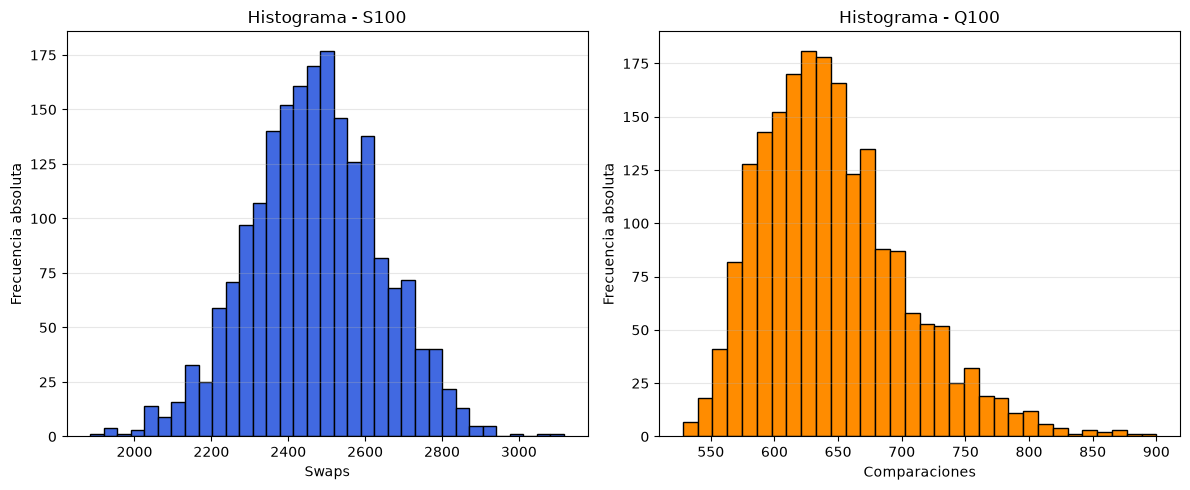

In [65]:
# Creamos la figura y los subgráficos (1 fila, 2 columnas)
figura, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# Histograma de S100 (Panel izquierdo)
columna1.hist(insertionSortUni[0], bins='auto', color='royalblue', edgecolor='black')
columna1.set_title('Histograma - S100')
columna1.set_xlabel('Swaps')
columna1.set_ylabel('Frecuencia absoluta')
columna1.grid(axis='y', alpha=0.3)

# Histograma de Q100 (Panel derecho)
columna2.hist(quickSortUni, bins='auto', color='darkorange', edgecolor='black')
columna2.set_title('Histograma - Q100')
columna2.set_xlabel('Comparaciones')
columna2.set_ylabel('Frecuencia absoluta')
columna2.grid(axis='y', alpha=0.3)

# Ajustar el diseño y mostrar
plt.tight_layout() # Evita que los márgenes y títulos se superpongan
plt.show()

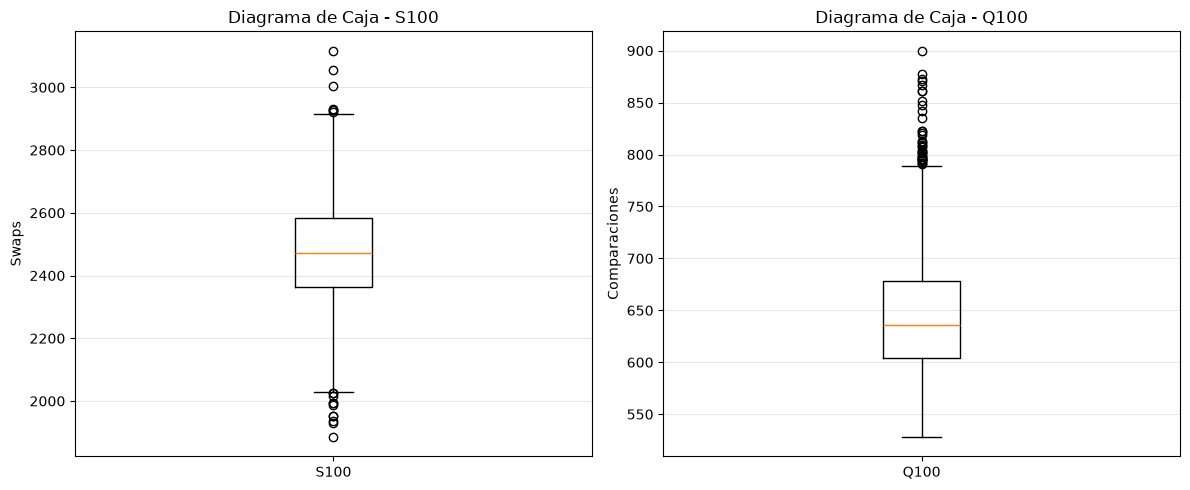

In [66]:
# Creamos la figura con 1 fila y 2 columnas
fig, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Boxplot de S100 (Panel izquierdo)
columna1.boxplot(insertionSortUni[0])
columna1.set_title('Diagrama de Caja - S100')
columna1.set_ylabel('Swaps')
columna1.set_xticks([1])
columna1.set_xticklabels(['S100'])
columna1.grid(axis='y', alpha=0.3)

# 2. Boxplot de Q100 (Panel derecho)
columna2.boxplot(quickSortUni)
columna2.set_title('Diagrama de Caja - Q100')
columna2.set_ylabel('Comparaciones')
columna2.set_xticks([1])
columna2.set_xticklabels(['Q100'])
columna2.grid(axis='y', alpha=0.3)

# Ajustamos y mostramos
plt.tight_layout()
plt.show()

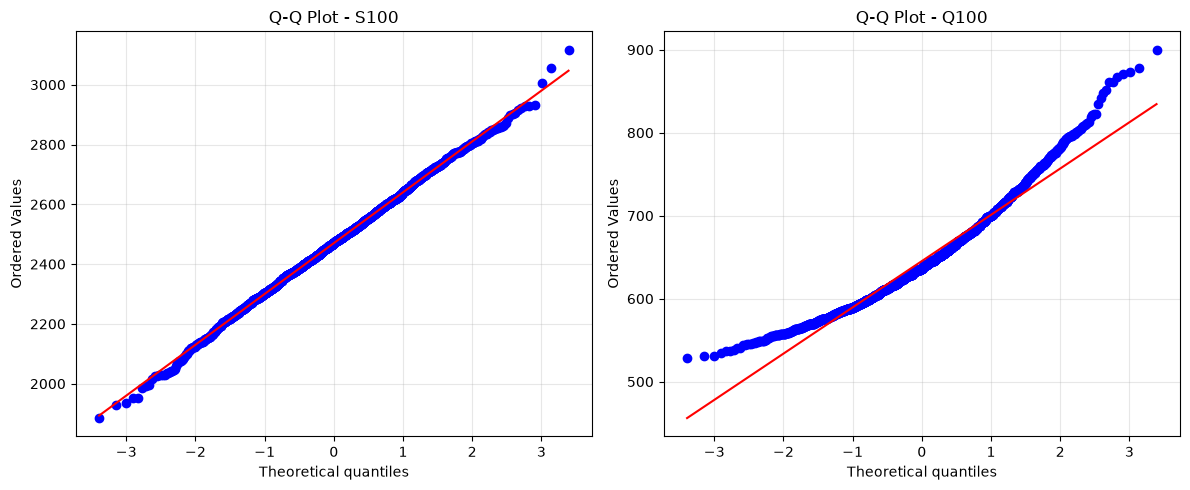

In [67]:
# Creamos la figura con 1 fila y 2 columnas
fig, (columna1, columna2) = plt.subplots(1, 2, figsize=(12, 5))

# 1. Q-Q plot para S100 (Panel izquierdo)
stats.probplot(insertionSortUni[0], dist="norm", plot=columna1)
columna1.set_title('Q-Q Plot - S100')
columna1.grid(alpha=0.3)

# 2. Q-Q plot para Q100 (Panel derecho)
stats.probplot(quickSortUni, dist="norm", plot=columna2)
columna2.set_title('Q-Q Plot - Q100')
columna2.grid(alpha=0.3)

# Ajustamos y mostramos
plt.tight_layout()
plt.show()

ii) Calcule media, desvío estándar, mediana, intervalo intercuartil y coeficiente de asimetría $\hat{\gamma}$.

In [68]:
def imprimir_estadisticos(datos, nombreVariable):
    media = np.mean(datos)
    desvio = np.std(datos, ddof=1) # desvio estandar
    mediana = np.median(datos)
    iqr = stats.iqr(datos) # intervalo intercuartil
    # bias=False ajusta el sesgo de la asimetría para muestras
    asimetria = stats.skew(datos) 
    
    print(f"--- Estadísticos de {nombreVariable} ---")
    print(f"Media:                      {media:.4f}")
    print(f"Desvío Estándar:            {desvio:.4f}")
    print(f"Mediana:                    {mediana:.4f}")
    print(f"Intervalo Intercuartil:     {iqr:.4f}")
    print(f"Coef. Asimetría (γ̂):        {asimetria:.4f}")
    print("-" * 40 + "\n")

imprimir_estadisticos(insertionSortUni[0], "S100")
imprimir_estadisticos(quickSortUni, "Q100")

--- Estadísticos de S100 ---
Media:                      2470.1320
Desvío Estándar:            169.8790
Mediana:                    2472.0000
Intervalo Intercuartil:     223.0000
Coef. Asimetría (γ̂):        -0.0339
----------------------------------------

--- Estadísticos de Q100 ---
Media:                      645.2840
Desvío Estándar:            56.8247
Mediana:                    636.0000
Intervalo Intercuartil:     74.2500
Coef. Asimetría (γ̂):        0.8308
----------------------------------------



### b) 
En la definición de $\gamma_X$, ¿por qué se eleva al cubo y no al cuadrado? ¿Por qué se divide por $\sigma^3$? ¿Cuánto vale $\gamma_X$ si la distribución de $X$ es simétrica alrededor de su media?

Definición de $\gamma_X = E \left[ \left( \frac{X-\mu}{\sigma}\right)^3  \right]$

i) ¿Por qué se eleva al cubo y no al cuadrado?

Se eleva al cubo para no perder el signo. La gracia del coeficiente de asimetría es que te dice si los valores se distribuyen de manera simétrica o si alguna cola concentra más valores, y te dice cuál. Si elevasemos al cuadrado, todos los numeros quedan positivos, perdiendo esa información.

ii) ¿Por qué se divide por $\sigma^3$?

Se divide por $\sigma^3$ para estandarizar el resultado. Esto le quita las unidades de medida (si las tiene) y lo hace independiente de la escala. Supongamos que medimos algo en milisegundos y otra en nanosegundos. Al usar el tercer momento, nos queda $ms^3$ en el primero, y $ns^3$ en el segundo. Como el $\sigma$ también contiene la unidad, al dividir se cancelan las unidades. Por otro lado, si no dividiéramos, el coeficiente de asimetría para el primero daría un número numéricamente mucho más grande que el segundo, pero no porque necesariamente esté mas deformado.

iii) ¿Cuánto vale $\gamma_X$ si la distribución de $X$ es simétrica alrededor de su media?

Si la distribución es simétrica, entonces $\gamma_X = 0$

### c)
¿Qué diferencias de forma observa entre $S_{100}$ y $Q_{100}$? ¿Es consistente la posición relativa de la media y la mediana con el valor de $\hat{\gamma}$? ¿Alguna de las dos distribuciones se parece a una conocida?

i) $S_{100}$ tiene un histograma que a simple vista parece simétrico. Sin embargo el histograma de $Q_{100}$ parece estar un poco más deformado, hay más valores concentrados a la izquierda, y una cola más larga y chata a la derecha.

ii) Sí, es consistente. Para $S_{100}$ la media y la mediana se encuentran muy centradas en el histograma, casi espejando un lado y el otro. Su coeficiente de asimetría es casi $0$, reflejando que la distribución es prácticamente normal.     
Por otro lado, para $Q_{100}$, la media y la mediana se encuentran corridas hacia la izquierda, donde se concentran la mayoría de los valores. Nuevamente es consistente con el coeficiente de asimetría que es casi 1. Recordemos que un $\hat{\gamma}>0$ indica una cola derecha más larga y los datos concentrados en valores más bajos. Justo como es el caso.

iii) Sí, $S_{100}$ es prácticamente una normal. $Q_{100}$ podría ser una gamma?

## Ejercicio 1.3
### a)  
Para $n = 3$, liste las $6$ permutaciones de $0, 1, 2$ y, para cada una, el vector $(V_1, V_2 , V_3)$ y el valor de $S_3$. ¿Es consistente la tabla con el dato? Calcule $E(S_3)$ y $Var(S_3)$ directamente de la tabla.

In [69]:
posiblesPermutaciones = [[0, 1, 2], [0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]
valoresInversiones = [[0, 0, 0], [0, 0, 1], [0, 1, 0], [0, 0, 2], [0, 1, 1], [0, 1, 2]]
cantidadSwaps = []

for elem in posiblesPermutaciones:
    swaps, _ = insertion_sort(elem)
    cantidadSwaps.append(swaps)

data = {
    'Permutacion': posiblesPermutaciones,
    'Inversiones': valoresInversiones,
    'S_3': cantidadSwaps
}

table = pd.DataFrame(data)

print(table, "\n")
print("Esperanza de S_3:", np.mean(cantidadSwaps))
print("Varianza de S_3:", np.var(cantidadSwaps, ddof=1))

  Permutacion Inversiones  S_3
0   [0, 1, 2]   [0, 0, 0]    0
1   [0, 2, 1]   [0, 0, 1]    1
2   [1, 0, 2]   [0, 1, 0]    1
3   [1, 2, 0]   [0, 0, 2]    2
4   [2, 0, 1]   [0, 1, 1]    2
5   [2, 1, 0]   [0, 1, 2]    3 

Esperanza de S_3: 1.5
Varianza de S_3: 1.1


Si, es consistente la tabla con el dato. 

### b)

Calcule $E(V_j)$ y $Var(V_j)$, y deduzca que

$ E[S_n] = \frac{n(n − 1)}{4}, \quad Var(S_n) = \frac{n(n − 1)(2n + 5)}{72} $

¿En qué paso usó la independencia? Verifique con el ítem a).

---

$ E[V_j] = \frac{(j-1) + 1}{2} = \frac{j}{2} $

$ Var(V_j) = \frac{j(j-2)}{12}$

Luego, calculemos $E[S_n]$ en función de $V_j$:

$ S_n = \sum_{j=0}^{n - 1}{V_j} $, entonces

$ E[S_n] = E[\sum_{j=0}^{n - 1}{V_j}] = \quad$ (por linealidad)

$ \sum_{j=0}^{n - 1} {E[V_j]} = \sum_{j=0}^{n - 1} {\frac{j}{2}} = \quad $ (suma de Gauss)

$ \frac{n(n-1)}{4} $

Veamos $Var(S_n)$:

$ Var(S_n) = Var(\sum_{j=0}^{n - 1}{V_j}) = \quad $ (porque son VAs independientes)

$ \sum_{j=0}^{n - 1}{Var(V_j)} = \sum_{j=0}^{n - 1}{\frac{j(j-2)}{12}} = $ 

$ \frac{1}{12} (\sum_{j=0}^{n - 1}{(j^2-2j)}) = \frac{1}{12} (\sum_{j=0}^{n - 1}{j^2} - 2\sum_{j=0}^{n-1}{j}) = \quad$ (suma de Gauss) 

$ \frac{1}{12} (\frac{n(n-1)(2n-1)}{6} - n(n-1)) = \frac{1}{12} (\frac{2n^3 - 3n^2 + n + 6n(n-1)}{6}) =  \frac{1}{12} (\frac{2n^3 + 3n^2 - 5n}{6}) =$

$ \frac{2n^3 + 3n^2 - 5n}{72} =$ 

$\frac{n(n-1)(2n+5)}{72}$

### c)

Compare $\mu_𝑆$ y $\sigma_𝑆^2$ con la media y la varianza muestrales del ítem 1.2. ¿De qué orden de magnitud esperaría que fuera la diferencia entre la media muestral y $\mu_S$?

In [70]:
mu_S = (100 * (100-1)) / 4
sigma2_S = (100*(100-1)*(2*100+5)) / 72
mediaMuestral = np.mean(insertionSortUni[0])
varianzaMuestral = np.var(insertionSortUni[0], ddof=1)
errorEstandarMedia = np.sqrt(sigma2_S/2000)
errorEstandarVarianza =  sigma2_S* np.sqrt(2/(2000-1))

print("La mu_S es:", mu_S)
print("La sigma2_S es:", sigma2_S)
print("La media muestral es:", mediaMuestral)
print("La varianza muestral es:",varianzaMuestral)

diferenciaMedias = abs(mu_S - mediaMuestral)
diferenciaVarianzas = abs(sigma2_S - varianzaMuestral)

print("\nLa diferencia entre medias es:", diferenciaMedias)
print("La diferencia entre varianzas es:", diferenciaVarianzas)

print("\nError estándar de las medias:", errorEstandarMedia)
print("Error estándar de las varianzas:", errorEstandarVarianza)

La mu_S es: 2475.0
La sigma2_S es: 28187.5
La media muestral es: 2470.132
La varianza muestral es: 28858.876014007

La diferencia entre medias es: 4.867999999999938
La diferencia entre varianzas es: 671.3760140070008

Error estándar de las medias: 3.754164354420302
Error estándar de las varianzas: 891.5899408143188


La diferencia entre las medias es de pocas unidades y la de las varianzas es de algunas centenas, lo que es razonable tomando en cuenta sus errores estandares. 
# (???)

### d)

Simule $𝑁 = 2000$ valores de $𝑆_{100}$ directamente desde el modelo, sumando $𝑉_𝑗$ uniformes independientes, sin correr ningún algoritmo de ordenamiento. Compare con los conteos de insertion sort mediante histogramas superpuestos y un gráfico cuantil-cuantil de una muestra contra la otra. ¿Qué esperaría ver si el modelo fuera correcto?

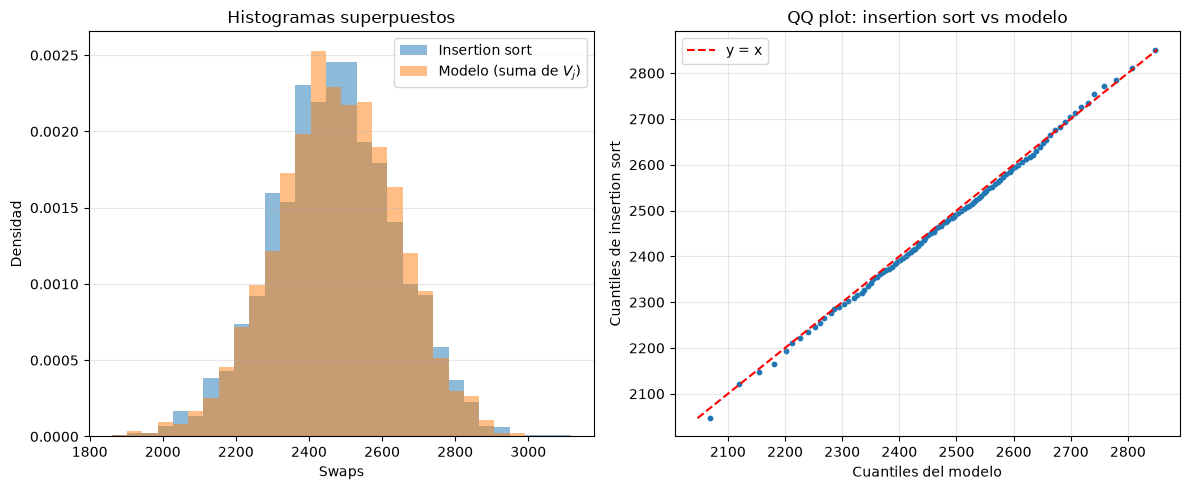

In [71]:
N, n = 2000, 100
# V_j ~ U{0,...,j-1} para j = 1..n, independientes; S_n = suma
# (np.arange(1, n+1) es el límite superior exclusivo de cada columna)
V = rng.integers(0, np.arange(1, n+1), size=(N, n))
swapsModelo = V.sum(axis=1)
swapsIS = np.array(insertionSortUni[0])   

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

bins = np.histogram_bin_edges(np.concatenate([swapsIS, swapsModelo]), bins=30)
ax1.hist(swapsIS, bins=bins, alpha=0.5, density=True, label="Insertion sort")
ax1.hist(swapsModelo, bins=bins, alpha=0.5, density=True, label="Modelo (suma de $V_j$)")
ax1.set_title("Histogramas superpuestos")
ax1.set_xlabel("Swaps")
ax1.set_ylabel("Densidad")
ax1.legend()
ax1.grid(axis="y", alpha=0.3)

p = np.linspace(0.01, 0.99, 99)
qIS, qModelo = np.quantile(swapsIS, p), np.quantile(swapsModelo, p)
ax2.scatter(qModelo, qIS, s=10)
lim = [min(qModelo.min(), qIS.min()), max(qModelo.max(), qIS.max())]
ax2.plot(lim, lim, "r--", label="y = x")
ax2.set_title("QQ plot: insertion sort vs modelo")
ax2.set_xlabel("Cuantiles del modelo")
ax2.set_ylabel("Cuantiles de insertion sort")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Esperaría ver una distribución similar en el histograma y el gráfico cuantil-cuantil debería ser similar a la recta $x = y$, que es lo que sucede.

### e)

Usando la estructura de $𝑆_𝑛$, explique por qué es razonable que su distribución sea aproximadamente normal. ¿Por qué no hay un argumento análogo para $𝑄_𝑛$?

---

Es razonable porque al ser una suma de variables independientes uniformes puedo aplicar el Teorema Central del Límite y decir que tiende a una Normal. 

# (???)

Para $ Q_n $ no se puede usar este argumento porque no se descompone en una suma de términos independientes y chicos, sino de forma recursiva, con subproblemas dependientes entre sí por el pivote.

## Ejercicio 1.4

### a)
Compare la media y la varianza muestrales de $𝑄_{100}$ con $mu_𝑄$ y $sigma^2_Q$ , calculadas con las fórmulas de la sección _Resultados conocidos_.

---

$mu_𝑄 = $ 
$sigma^2_Q$